In [2]:
import pandas as pd
import matplotlib.pyplot as plt
# import seaborn as sns

In [4]:
results_df = pd.read_csv("results_1.csv")

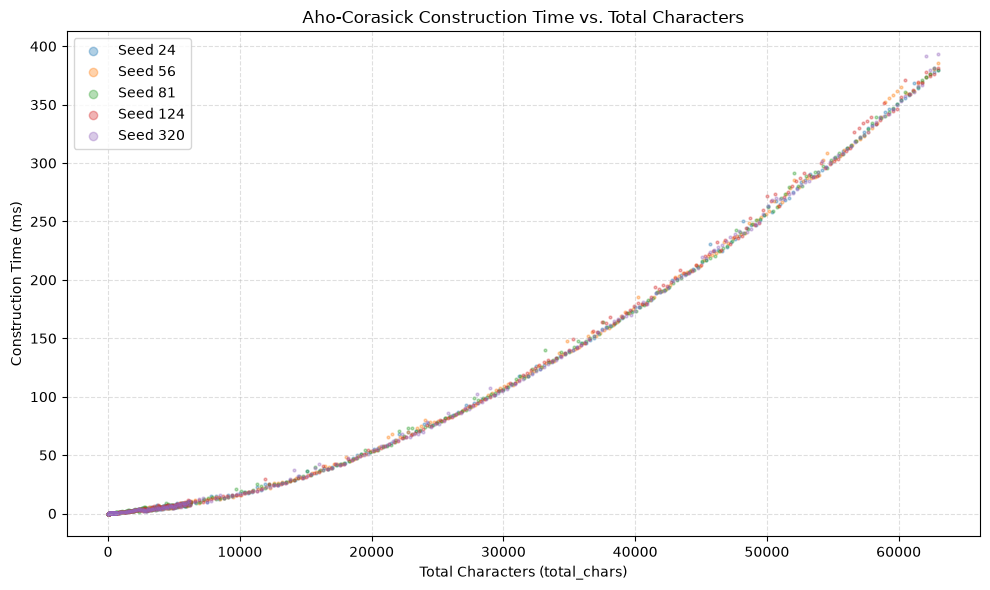

In [11]:
fig, ax = plt.subplots(figsize=(10, 6))

for seed, group in results_df.groupby("seed"):
    ax.scatter(
        group["total_chars"],
        group["Construction_us"] / 1000,  # Convert ns to ms for cleaner axis labels
        label=f"Seed {seed}",
        s=4,        # Small point size prevents overplotting across thousands of rows
        alpha=0.35, # Transparency reveals point density and OS jitter spikes
    )

ax.set_title("Aho-Corasick Construction Time vs. Total Characters")
ax.set_xlabel("Total Characters (total_chars)")
ax.set_ylabel("Construction Time (ms)")
ax.legend(markerscale=3)
ax.grid(True, linestyle="--", alpha=0.4)

# Optional: uncomment to prevent rare OS scheduling spikes from squashing the linear trend
# ax.set_ylim(0, (results_df["Construction_us"] / 1000).quantile(0.995))

plt.tight_layout()
plt.show()

In [28]:
def generate_plots(df: pd.DataFrame, x_col:str, y_col:str, Title:str|None="Title", xLabel:str | None="X-axis",yLabel:str | None="Y-axis"):
    # hue_col: str | None = "seed",
    # y_scale: float = 1.0,
    # y_unit: str | None = None,
    # clip_quantile: float | None = None,
    # figsize: tuple[int, int] = (10, 6),
    # dpi: int = 150
    
    fig, ax = plt.subplots(figsize=(10, 6))
    
    for seed, group in df.groupby("seed"):
        ax.scatter(
            group[x_col],
            group[y_col],  # Convert ns to ms for cleaner axis labels
            label=f"Seed {seed}",
            s=4,        # Small point size prevents overplotting across thousands of rows
            alpha=0.35, # Transparency reveals point density and OS jitter spikes
        )
    
    ax.set_title(Title)
    ax.set_xlabel(xLabel)
    ax.set_ylabel(yLabel)
    ax.legend(markerscale=3)
    ax.grid(True, linestyle="--", alpha=0.4)
    
    # Optional: uncomment to prevent rare OS scheduling spikes from squashing the linear trend
    # ax.set_ylim(0, (results_df["Construction_us"] / 1000).quantile(0.995))
    
    fig.tight_layout()
    plt.close(fig)
    return fig

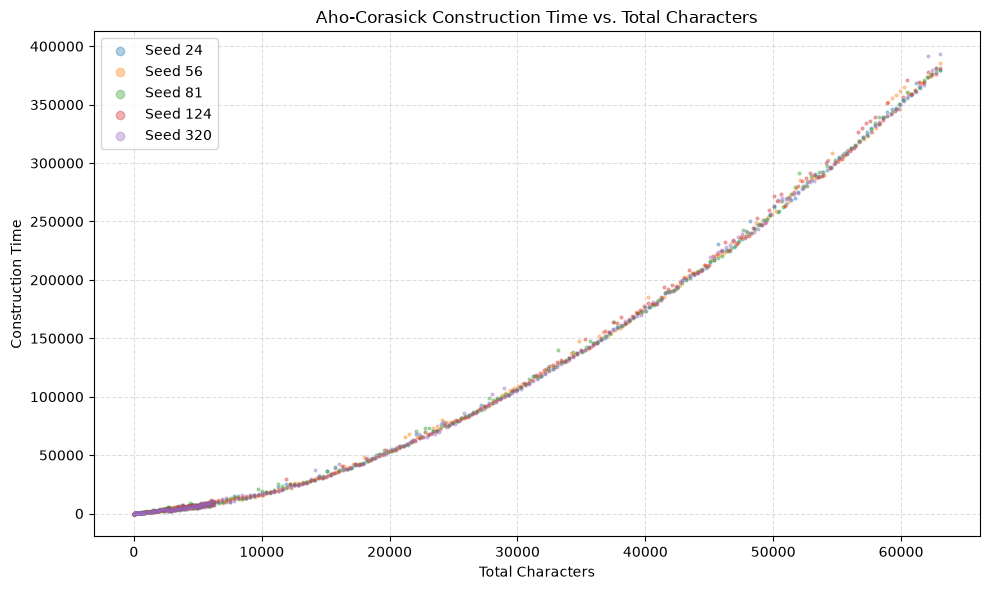

In [29]:
fig1 = generate_plots(results_df, x_col="total_chars", y_col="Construction_us", 
                      xLabel = "Total Characters",
                      yLabel = "Construction Time",
                      Title = "Aho-Corasick Construction Time vs. Total Characters")

display(fig1)

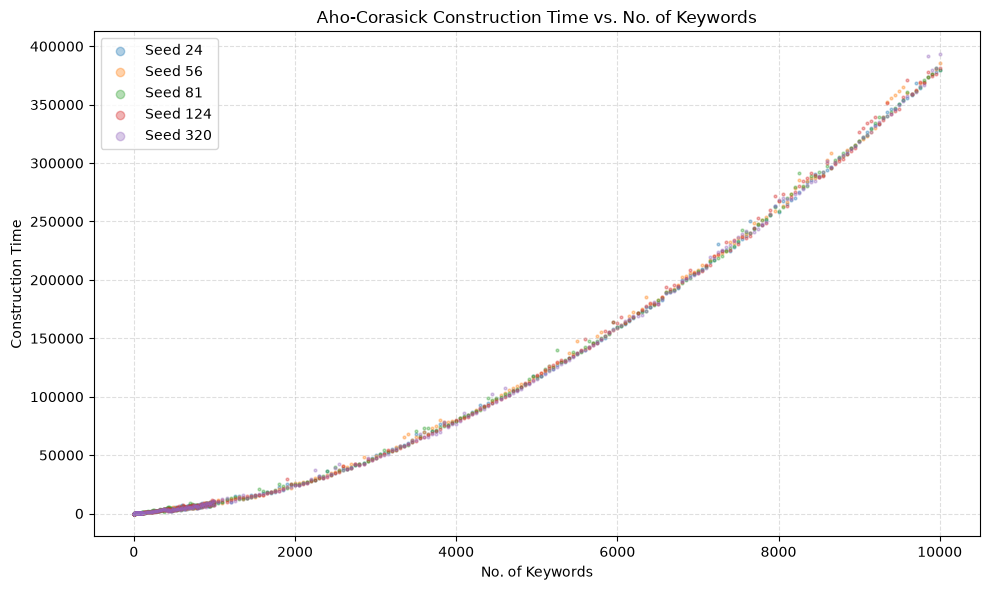

In [20]:
fig2 = generate_plots(results_df, x_col="num_keywords", y_col="Construction_us", 
                      xLabel = "No. of Keywords",
                      yLabel = "Construction Time",
                      Title = "Aho-Corasick Construction Time vs. No. of Keywords")

display(fig2)

In [17]:
results_df.columns

Index(['seed', 'num_keywords', 'total_chars', 'node_count', 'encode_ns',
       'ac_init_ns', 'goto_ns', 'fail_ns', 'Construction', 'Construction_us'],
      dtype='str')

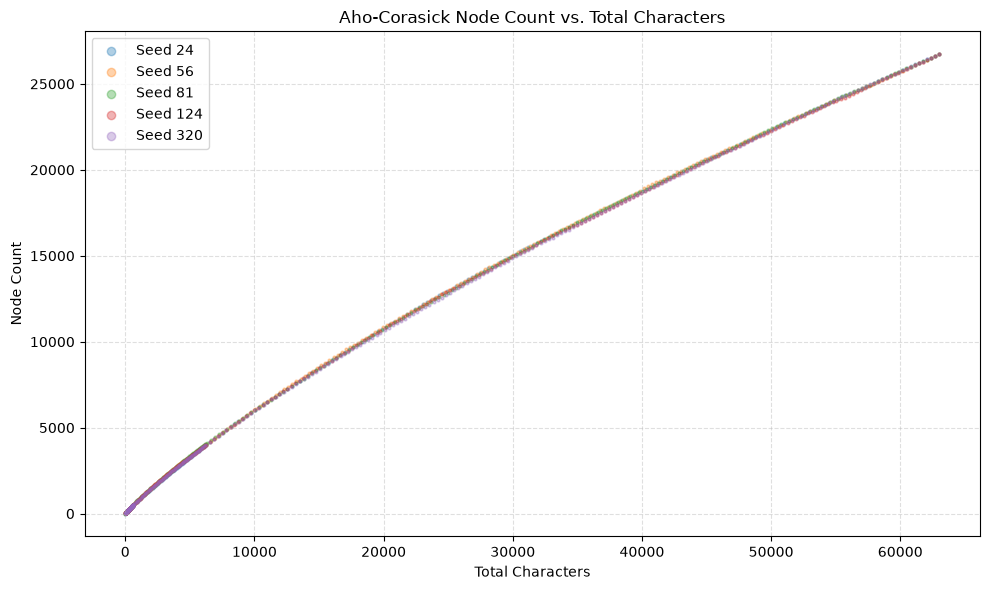

In [21]:
fig3 = generate_plots(results_df, x_col="total_chars", y_col="node_count", 
                      xLabel = "Total Characters",
                      yLabel = "Node Count",
                      Title = "Aho-Corasick Node Count vs. Total Characters")

display(fig3)

In [23]:
results_df_2 = pd.read_csv("results_2.csv")

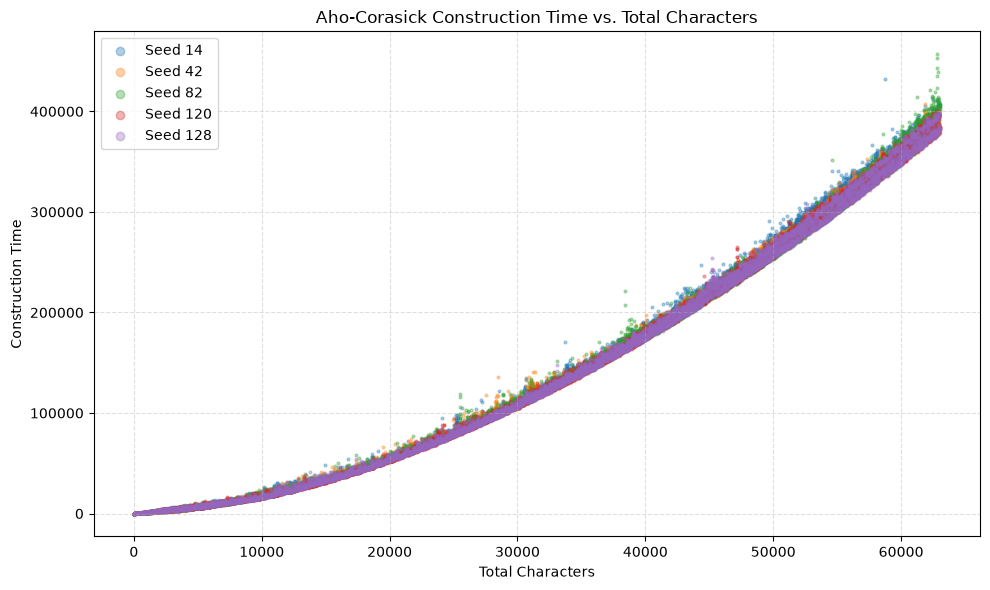

In [30]:
fig21 = generate_plots(results_df_2, x_col="total_chars", y_col="Construction_us", 
                      xLabel = "Total Characters",
                      yLabel = "Construction Time",
                      Title = "Aho-Corasick Construction Time vs. Total Characters")

display(fig21)